# Data Exploration + Baseline Models (1 & 2)

This notebook is the "explained" version of `src/nlp/dataset.py` and `src/nlp/train_baselines.py`,
written as a step-by-step walkthrough instead of importable functions.

**Dataset: SEntFiN-v1.1** — 10,753 Indian financial news headlines with entity-level sentiment
(e.g. `{"SpiceJet": "neutral"}`). Chosen over the other candidates evaluated (a raw Indian-news scrape
with noisy auto-labels, a binary weakly-labeled corpus, and a stock-direction-prediction dataset that
doesn't match this task) because it's the only one that is both human-annotated and reasonably balanced
across all three sentiment classes.

**What it does:**
1. Load SEntFiN, resolve multi-entity headlines to one headline-level label
2. Look at the data (EDA) — label balance, headline lengths, sample rows, entities-per-headline
3. Split into train / val / test, and save all three to CSV (downstream notebooks reuse these)
4. Clean the text (stopword removal) for the analysis steps below
5. Deeper EDA — KDE plots, box plot, scatter plot
6. Work out the best vocabulary size from the actual data instead of guessing
7. Bag-of-Words + most frequent words
8. Top bigrams & trigrams
9. Word clouds
10. Train Model 1: TF-IDF + Logistic Regression
11. Train Model 2: TF-IDF + XGBoost
12. Compare the two


In [1]:
# ── the few libraries this notebook needs ──
import re
import os
import ast
import time
import pickle
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

import mlflow

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ── constants (same values as src/config.py, so results line up with the rest of the project) ──
LABEL2ID = {"positive": 0, "neutral": 1, "negative": 2}
ID2LABEL = {0: "positive", 1: "neutral", 2: "negative"}
LABEL_COLORS = {"positive": "#4ade80", "neutral": "#fbbf24", "negative": "#f87171"}

VOCAB_SIZE = 30_000
MAX_LENGTH = 128
PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
PAD_IDX, UNK_IDX = 0, 1

SEED = 42
TEST_SIZE = 0.15
VAL_SIZE = 0.10

MLFLOW_EXPERIMENT = "IndianFinSentiment"

random.seed(SEED)
np.random.seed(SEED)

RESULTS_DIR = "results"
MODELS_DIR = "saved_models"
DATA_DIR = "../data/processed"     # this notebook lives in notebooks/, project data/ is one level up
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)


def resolve_sentifin_path():
    """Find SEntFiN-v1.1.csv: Kaggle input mount first, then the local repo's data/ dirs."""
    candidates = [
        "/kaggle/input/sentfin/SEntFiN-v1.1.csv",
        "../data/raw/SEntFiN-v1.1.csv",
        "../data/SEntFiN-v1.1.csv",
    ]
    if os.path.isdir("/kaggle/input"):
        for root, _, files in os.walk("/kaggle/input"):
            for f in files:
                if f == "SEntFiN-v1.1.csv":
                    candidates.insert(0, os.path.join(root, f))
    for path in candidates:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(
        "SEntFiN-v1.1.csv not found. Place it at data/raw/SEntFiN-v1.1.csv (local) "
        "or attach it as a Kaggle dataset input (Kaggle)."
    )


mlflow.set_tracking_uri(f"sqlite:///mlflow.db")   # MLflow 3.x default; keeps metrics/params in one file

## Step 1 — Load the data

SEntFiN-v1.1 gives entity-level sentiment per headline, e.g. `{"SpiceJet": "neutral"}`, and ~26% of
headlines mention more than one entity. Since every model in this project classifies a whole headline
as a single label (none of them are entity-aware), we resolve each headline to one label by keeping only
headlines where every entity mentioned shares the same sentiment (trivially true when there's just one
entity) and dropping the ones where entities genuinely disagree — those are ambiguous for a single-label
classifier, not something the model itself could ever learn correctly.

In [3]:
def load_sentifin():
    """SEntFiN-v1.1: entity-level Indian financial headline sentiment, resolved to one label/headline."""
    csv_path = resolve_sentifin_path()
    raw = pd.read_csv(csv_path)
    print(f"Raw SEntFiN rows: {len(raw)}")

    texts, labels, n_entities = [], [], []
    dropped_conflicting = 0
    for _, row in raw.iterrows():
        try:
            decisions = ast.literal_eval(row["Decisions"])
        except (ValueError, SyntaxError):
            continue
        if not decisions:
            continue
        unique_labels = set(decisions.values())
        if len(unique_labels) != 1:
            dropped_conflicting += 1
            continue
        texts.append(row["Title"])
        labels.append(unique_labels.pop())
        n_entities.append(len(decisions))

    df = pd.DataFrame({"text": texts, "label": labels, "n_entities": n_entities})
    df["label"] = df["label"].str.lower().str.strip()
    df = df[df["label"].isin(LABEL2ID.keys())]
    df["label_id"] = df["label"].map(LABEL2ID)
    df["source"] = "sentifin"

    print(f"Dropped {dropped_conflicting} headlines with conflicting entity sentiment "
          f"({dropped_conflicting / len(raw) * 100:.1f}% of raw rows)")
    return df[["text", "label", "label_id", "source", "n_entities"]]


# ── load and clean ──
df = load_sentifin()

df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"].str.len() > 10]          # drop near-empty rows
df = df[df["text"].str.len() < 1000]        # drop unusually long rows
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

print(f"\nTotal headlines after cleaning: {len(df)}")
print(f"Headlines with >1 entity: {(df['n_entities'] > 1).sum()} "
      f"({(df['n_entities'] > 1).mean() * 100:.1f}%)")

Raw SEntFiN rows: 10753


Dropped 1235 headlines with conflicting entity sentiment (11.5% of raw rows)

Total headlines after cleaning: 9459
Headlines with >1 entity: 1608 (17.0%)


## Step 2 — Look at the data (EDA)

Before training anything, always look at your data: is it balanced? How long are the headlines? What do a few examples actually look like?

In [4]:
# ── label balance ──
print("Label distribution:")
for label, count in df["label"].value_counts().items():
    bar = "#" * int(count / len(df) * 50)
    print(f"  {label:>10}: {count:>6} ({count/len(df)*100:4.1f}%)  {bar}")

# ── headline length ──
df["word_count"] = df["text"].str.split().str.len()
df["char_count"] = df["text"].str.len()
print(f"\nHeadline word count — mean: {df['word_count'].mean():.1f}, max: {df['word_count'].max()}")

# ── a few real examples per class, just to sanity-check the labels make sense ──
for label in ["positive", "neutral", "negative"]:
    print(f"\n[{label.upper()}] examples:")
    for text in df[df["label"] == label]["text"].sample(2, random_state=SEED):
        print(f"  - {text[:100]}")

Label distribution:
     neutral:   3407 (36.0%)  ##################
    positive:   3352 (35.4%)  #################
    negative:   2700 (28.5%)  ##############

Headline word count — mean: 9.8, max: 23

[POSITIVE] examples:
  - Cadila Healthcare beats estimates with 81% jump in Q3 profit, stock up 2%
  - Shree Cement net profit surge by 537% on better realisations, operational efficiencies

[NEUTRAL] examples:
  - Videocon D2H likely to bring IPO this fiscal
  - Pre-market: Nifty seen opening flat; Kotak Mahindra eyed

[NEGATIVE] examples:
  - RNRL is a clear sell: Seshadri Bharathan
  - Even luxury goods makers like Apple, BMW , Daimler not immune to yuan swings


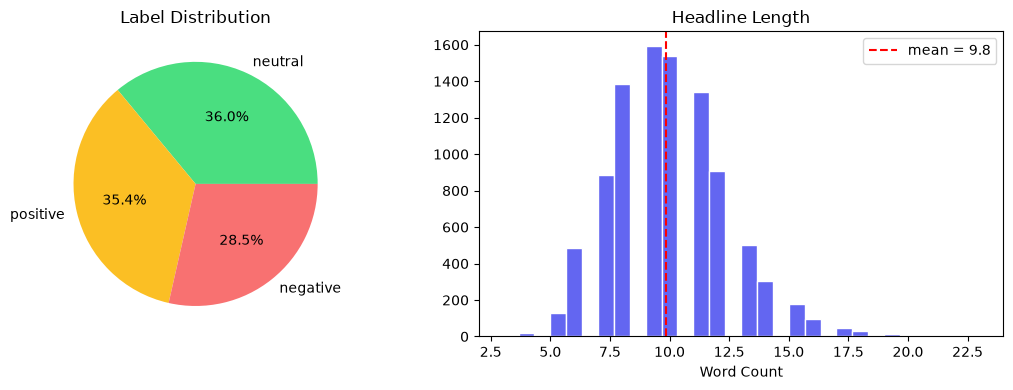

In [5]:
# ── two quick plots: label balance + headline length ──
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = df["label"].value_counts()
axes[0].pie(counts.values, labels=counts.index, autopct="%1.1f%%",
            colors=["#4ade80", "#fbbf24", "#f87171"])
axes[0].set_title("Label Distribution")

axes[1].hist(df["word_count"], bins=30, color="#6366f1", edgecolor="white")
axes[1].axvline(df["word_count"].mean(), color="red", linestyle="--",
                 label=f"mean = {df['word_count'].mean():.1f}")
axes[1].set_xlabel("Word Count")
axes[1].set_title("Headline Length")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/eda_plots.png", dpi=120, bbox_inches="tight")
plt.show()

Entities per headline:
  1 entity:   7851 (83.0%)
  2 entities:   1268 (13.4%)
  3 entities:    263 ( 2.8%)
  4 entities:     57 ( 0.6%)
  5 entities:     17 ( 0.2%)
  6 entities:      3 ( 0.0%)


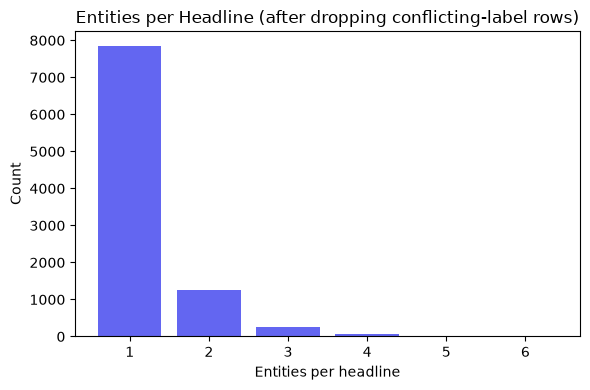

In [6]:
# ── SEntFiN-specific: how many entities does a headline usually mention? ──
entity_counts = df["n_entities"].value_counts().sort_index()
print("Entities per headline:")
for n, count in entity_counts.items():
    print(f"  {n} entit{'y' if n == 1 else 'ies'}: {count:>6} ({count / len(df) * 100:4.1f}%)")

plt.figure(figsize=(6, 4))
plt.bar(entity_counts.index.astype(str), entity_counts.values, color="#6366f1")
plt.xlabel("Entities per headline")
plt.ylabel("Count")
plt.title("Entities per Headline (after dropping conflicting-label rows)")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/entities_per_headline.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 3 — Split into train / val / test, and save to CSV

We stratify on the label so all three splits keep the same positive/neutral/negative balance. Saving these to disk now means every notebook after this one (`bow_vs_tfidf.ipynb`, the classical-ML hyperparameter-tuning notebooks, etc.) trains and evaluates on the exact same rows — a fair comparison instead of each notebook re-fetching and re-splitting the data slightly differently.

In [7]:
train_val_df, test_df = train_test_split(
    df, test_size=TEST_SIZE, stratify=df["label_id"], random_state=SEED
)
train_df, val_df = train_test_split(
    train_val_df, test_size=VAL_SIZE / (1 - TEST_SIZE),
    stratify=train_val_df["label_id"], random_state=SEED
)

print(f"Train: {len(train_df)}  |  Val: {len(val_df)}  |  Test: {len(test_df)}")

# ── save so every later notebook can just read these instead of reloading from HuggingFace ──
train_df.to_csv(f"{DATA_DIR}/train.csv", index=False)
val_df.to_csv(f"{DATA_DIR}/val.csv", index=False)
test_df.to_csv(f"{DATA_DIR}/test.csv", index=False)
df.to_csv(f"{DATA_DIR}/full_cleaned.csv", index=False)
print(f"Saved train.csv / val.csv / test.csv / full_cleaned.csv to {DATA_DIR}/")

Train: 7094  |  Val: 946  |  Test: 1419


Saved train.csv / val.csv / test.csv / full_cleaned.csv to ../data/processed/


## Step 4 — Clean the text (for the analysis steps below only)

TF-IDF (Models 1 & 2 further down) doesn't need this — its own IDF weighting already downweights common
words like "the", and it's fit directly on the raw `text` column. This cleaned version exists **only** for
the word-frequency-style plots in the next few steps (word cloud, bigrams, trigrams, top words) — without
removing stopwords, those plots would just show "the", "a", "of", "in" as the "top words," which isn't
useful. So: raw `text` feeds the models below, `clean_text` only feeds the plots below.

In [8]:
def clean_for_analysis(text):
    """Lowercase, strip punctuation/numbers, drop stopwords and very short words."""
    text = text.lower()
    text = re.sub(r"https?://\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    words = [w for w in text.split() if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return " ".join(words)


df["clean_text"] = df["text"].apply(clean_for_analysis)

print("Before vs after cleaning:")
for _, row in df.sample(2, random_state=SEED).iterrows():
    print(f"\n  original : {row['text'][:100]}")
    print(f"  cleaned  : {row['clean_text'][:100]}")

Before vs after cleaning:

  original : Petronet stocks undergo lots of fluctuations, recommended only for traders: G Chokkalingam
  cleaned  : petronet stocks undergo lots fluctuations recommended traders chokkalingam

  original : Volkswagen shares plunge the most in six years on US emission scandal
  cleaned  : volkswagen shares plunge years emission scandal


## Step 5 — Deeper EDA: KDE, box plot, scatter plot

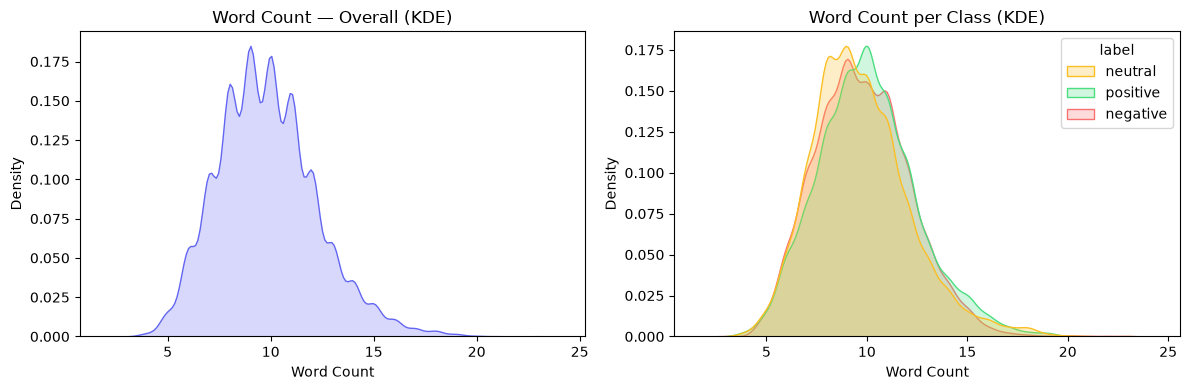

In [9]:
# ── KDE: overall word-count distribution, and one line per class ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(df["word_count"], fill=True, ax=axes[0], color="#6366f1")
axes[0].set_title("Word Count — Overall (KDE)")
axes[0].set_xlabel("Word Count")

sns.kdeplot(data=df, x="word_count", hue="label", fill=True, common_norm=False,
            palette=LABEL_COLORS, ax=axes[1])
axes[1].set_title("Word Count per Class (KDE)")
axes[1].set_xlabel("Word Count")

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/kde_word_count.png", dpi=120, bbox_inches="tight")
plt.show()

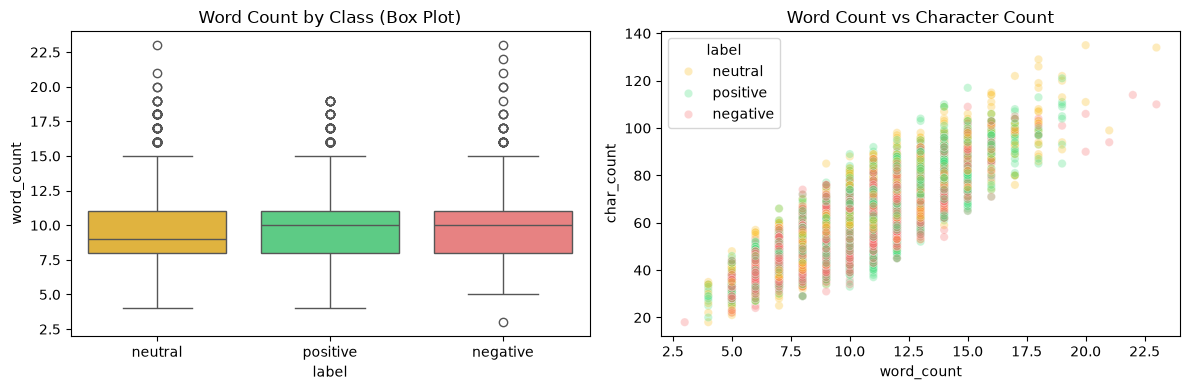

In [10]:
# ── box plot: word count spread per class ──
# ── scatter plot: word count vs character count, colored by class ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="label", y="word_count", hue="label",
            palette=LABEL_COLORS, legend=False, ax=axes[0])
axes[0].set_title("Word Count by Class (Box Plot)")

sns.scatterplot(data=df, x="word_count", y="char_count", hue="label",
                 palette=LABEL_COLORS, alpha=0.3, ax=axes[1])
axes[1].set_title("Word Count vs Character Count")

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/box_scatter.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 6 — Finding the best vocabulary size

Every notebook so far has just hardcoded `VOCAB_SIZE = 30_000` — the top-N most frequent words the
tokenizer keeps before falling back to `<UNK>`. Let's actually check whether that number makes sense for
this dataset, instead of assuming it. We fit only on `train_df` (never val/test — same reasoning as the
tokenizer notebooks: don't let the vocabulary "see" data it'll later be evaluated on).

In [11]:
def simple_tokenize(text):
    """Same tokenization the word2idx tokenizer uses in the deep-learning notebooks — kept
    consistent here so this vocab-size analysis is measuring the right thing."""
    text = text.lower()
    text = re.sub(r"https?://\S+", "", text)
    text = re.sub(r"[^a-z0-9\s\-\%\.]", " ", text)
    return text.split()


word_counts = Counter()
for text in train_df["text"]:
    word_counts.update(simple_tokenize(text))

freqs = np.array(sorted(word_counts.values(), reverse=True))
cumulative_coverage = np.cumsum(freqs) / freqs.sum()

print(f"Total unique words in training data: {len(freqs)}")
for v in [1000, 5000, 10000, 15000, 20000, 25000, 30000]:
    v = min(v, len(freqs))
    print(f"  vocab_size={v:>6} -> covers {cumulative_coverage[v - 1] * 100:5.2f}% of all word occurrences")

best_95 = int(np.searchsorted(cumulative_coverage, 0.95) + 1)
best_99 = int(np.searchsorted(cumulative_coverage, 0.99) + 1)
print(f"\nVocab size needed for 95% coverage: {best_95}")
print(f"Vocab size needed for 99% coverage: {best_99}")
current_coverage = cumulative_coverage[min(VOCAB_SIZE, len(freqs)) - 1] * 100
print(f"Current VOCAB_SIZE constant used everywhere else in this project: {VOCAB_SIZE}")
print(f"-> {VOCAB_SIZE} covers {current_coverage:.2f}% of all word occurrences.")
if VOCAB_SIZE >= best_99:
    print(f"   That's above the {best_99} needed for 99% coverage — {VOCAB_SIZE} has headroom to spare.")
else:
    print(f"   99% coverage would need {best_99} — slightly more than the current {VOCAB_SIZE}.")

Total unique words in training data: 9341
  vocab_size=  1000 -> covers 72.60% of all word occurrences
  vocab_size=  5000 -> covers 93.83% of all word occurrences
  vocab_size=  9341 -> covers 100.00% of all word occurrences
  vocab_size=  9341 -> covers 100.00% of all word occurrences
  vocab_size=  9341 -> covers 100.00% of all word occurrences
  vocab_size=  9341 -> covers 100.00% of all word occurrences
  vocab_size=  9341 -> covers 100.00% of all word occurrences

Vocab size needed for 95% coverage: 5824
Vocab size needed for 99% coverage: 8638
Current VOCAB_SIZE constant used everywhere else in this project: 30000
-> 30000 covers 100.00% of all word occurrences.
   That's above the 8638 needed for 99% coverage — 30000 has headroom to spare.


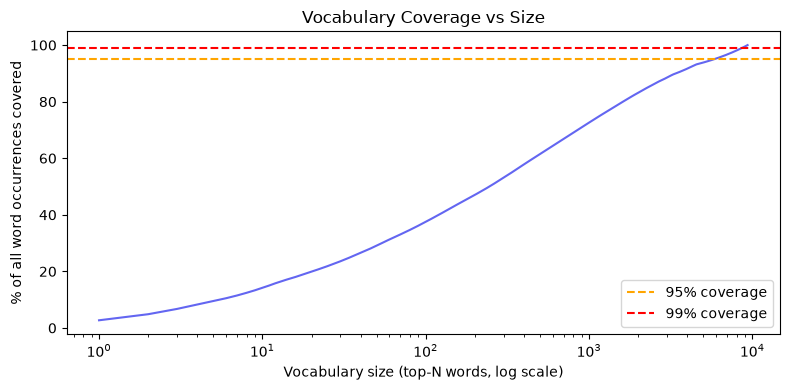

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumulative_coverage) + 1), cumulative_coverage * 100, color="#6366f1")
plt.axhline(95, color="orange", linestyle="--", label="95% coverage")
plt.axhline(99, color="red", linestyle="--", label="99% coverage")
plt.xscale("log")
plt.xlabel("Vocabulary size (top-N words, log scale)")
plt.ylabel("% of all word occurrences covered")
plt.title("Vocabulary Coverage vs Size")
plt.legend()
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/vocab_coverage.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 7 — Bag-of-Words (CountVectorizer) + most frequent words

Bag-of-Words vocabulary size: 7738
Bag-of-Words matrix shape: (9459, 7738)  (rows=headlines, cols=vocabulary)


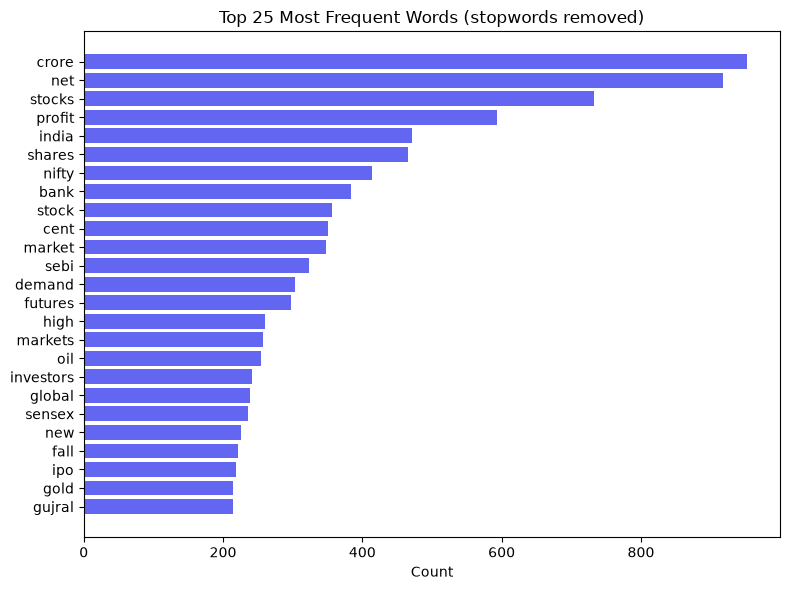

In [13]:
bow_vectorizer = CountVectorizer(max_features=15_000, stop_words="english")
bow_matrix = bow_vectorizer.fit_transform(df["clean_text"])
print(f"Bag-of-Words vocabulary size: {len(bow_vectorizer.vocabulary_)}")
print(f"Bag-of-Words matrix shape: {bow_matrix.shape}  (rows=headlines, cols=vocabulary)")

word_freq = np.asarray(bow_matrix.sum(axis=0)).ravel()
words = bow_vectorizer.get_feature_names_out()
top25_idx = np.argsort(word_freq)[::-1][:25]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([words[i] for i in top25_idx][::-1], [word_freq[i] for i in top25_idx][::-1], color="#6366f1")
ax.set_title("Top 25 Most Frequent Words (stopwords removed)")
ax.set_xlabel("Count")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/top25_words.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 8 — Top bigrams & trigrams

Single words only tell you so much — pairs and triples of words ("interest rate", "record quarterly profit") often carry more specific meaning.

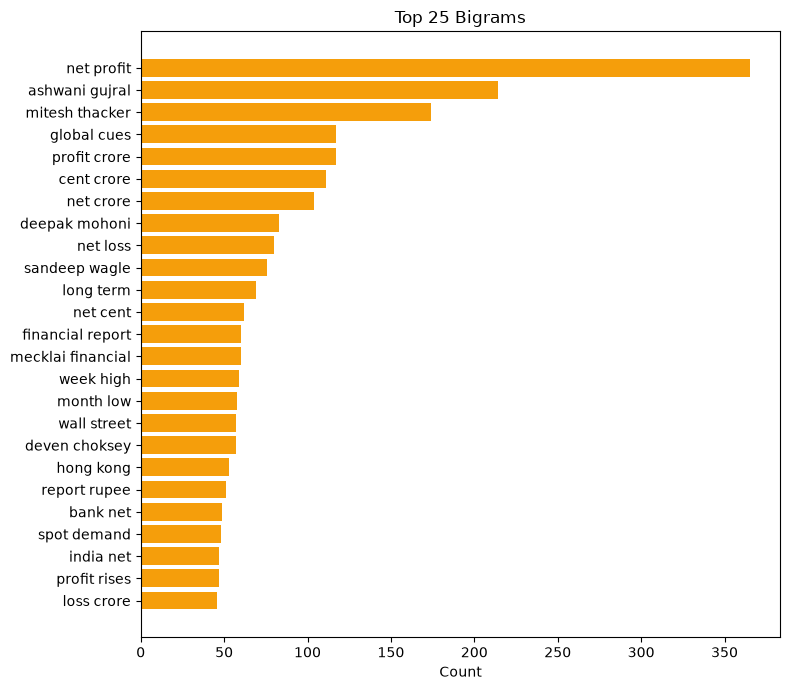

In [14]:
def plot_top_ngrams(texts, ngram_range, title, color, top_n=25):
    vec = CountVectorizer(ngram_range=ngram_range, stop_words="english", max_features=5000)
    matrix = vec.fit_transform(texts)
    freqs = np.asarray(matrix.sum(axis=0)).ravel()
    terms = vec.get_feature_names_out()
    top_idx = np.argsort(freqs)[::-1][:top_n]

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.barh([terms[i] for i in top_idx][::-1], [freqs[i] for i in top_idx][::-1], color=color)
    ax.set_title(title)
    ax.set_xlabel("Count")
    plt.tight_layout()
    path = f"{RESULTS_DIR}/{title.lower().replace(' ', '_')}.png"
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()


plot_top_ngrams(df["clean_text"], (2, 2), "Top 25 Bigrams", "#f59e0b")

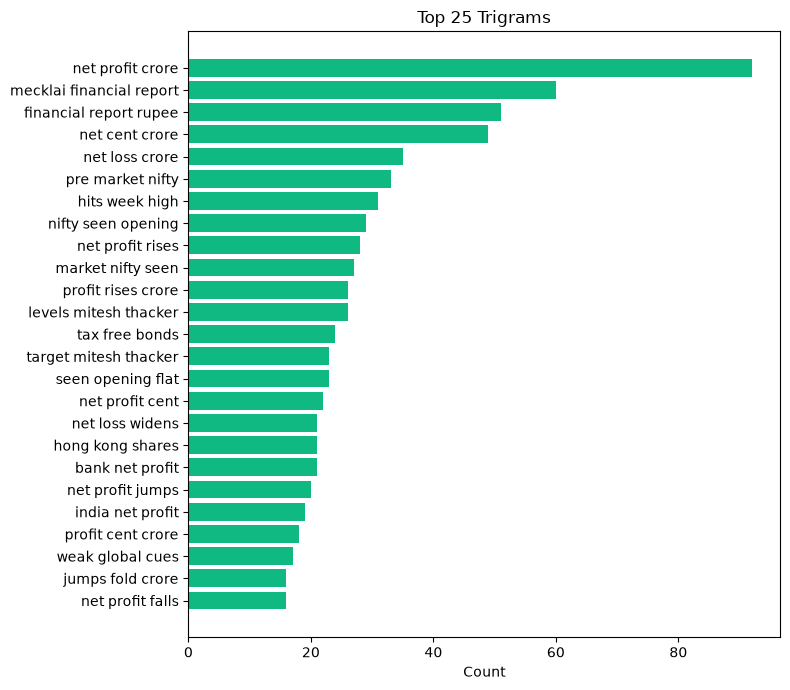

In [15]:
plot_top_ngrams(df["clean_text"], (3, 3), "Top 25 Trigrams", "#10b981")

## Step 9 — Word clouds

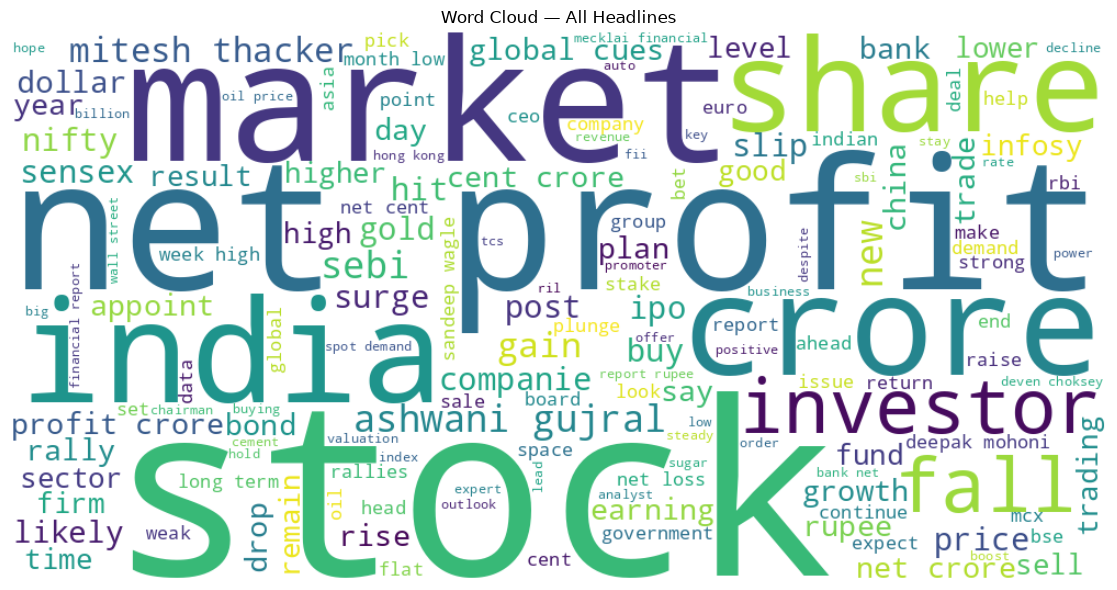

In [16]:
all_text = " ".join(df["clean_text"])
wc = WordCloud(width=1000, height=500, background_color="white",
               colormap="viridis", max_words=150).generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud — All Headlines")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/wordcloud_overall.png", dpi=120, bbox_inches="tight")
plt.show()

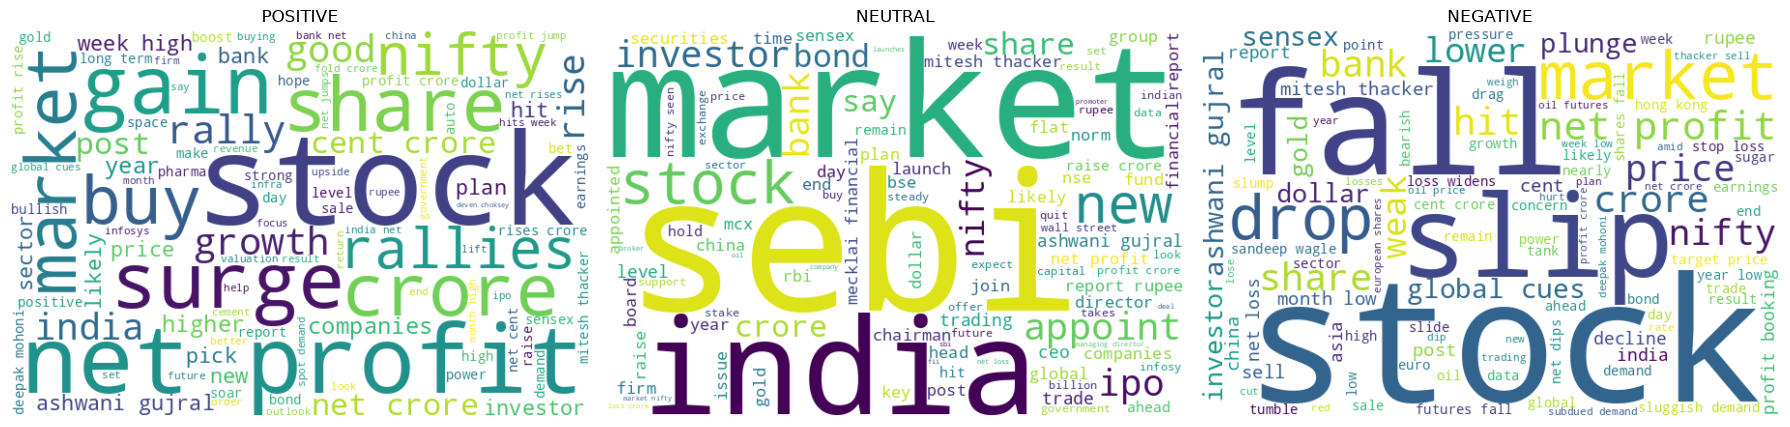

In [17]:
# ── one word cloud per class, side by side — see if each class has a distinct vocabulary ──
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, label in zip(axes, ["positive", "neutral", "negative"]):
    text_for_label = " ".join(df[df["label"] == label]["clean_text"])
    wc_label = WordCloud(width=600, height=400, background_color="white",
                          colormap="viridis", max_words=100).generate(text_for_label)
    ax.imshow(wc_label, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(label.upper())

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/wordcloud_per_class.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 10 — Model 1: TF-IDF + Logistic Regression

Our simplest baseline. TF-IDF turns each headline into a vector where rare, informative words (like *"inflation"*) get more weight than common ones (like *"the"*). Logistic Regression then draws a simple linear boundary between the three classes.

Every deep learning model later in this project has to beat this number.

In [18]:
def evaluate(y_true, y_pred):
    per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2])
    return {
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "f1_weighted": round(f1_score(y_true, y_pred, average="weighted"), 4),
        "f1_positive": round(per_class[0], 4),
        "f1_neutral": round(per_class[1], 4),
        "f1_negative": round(per_class[2], 4),
    }


def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1)[:, None]
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm_pct, annot=True, fmt=".1%", cmap="Blues",
                xticklabels=["positive", "neutral", "negative"],
                yticklabels=["positive", "neutral", "negative"], ax=ax)
    ax.set_title(f"Confusion Matrix - {model_name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    path = f"{RESULTS_DIR}/cm_{model_name.lower().replace(' ', '_')}.png"
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()
    return path


mlflow.set_experiment(MLFLOW_EXPERIMENT)

<Experiment: artifact_location='/Users/vijay/Desktop/sentiment-drl-trading/notebooks/mlruns/1', creation_time=1784125157925, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1784125157925, lifecycle_stage='active', name='IndianFinSentiment', tags={}, trace_location=None, workspace='default'>

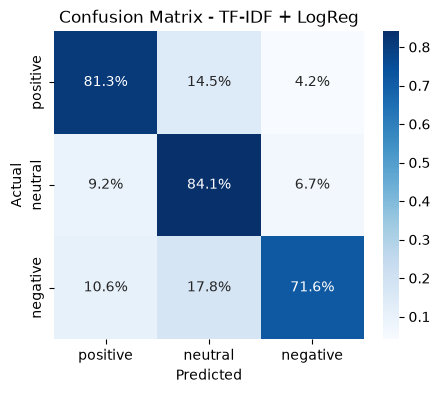

TF-IDF + LogReg: {'accuracy': 0.7956, 'f1_weighted': 0.7953, 'f1_positive': np.float64(0.8164), 'f1_neutral': np.float64(0.7919), 'f1_negative': np.float64(0.7733)}
              precision    recall  f1-score   support

    positive       0.82      0.81      0.82       503
     neutral       0.75      0.84      0.79       511
    negative       0.84      0.72      0.77       405

    accuracy                           0.80      1419
   macro avg       0.80      0.79      0.79      1419
weighted avg       0.80      0.80      0.80      1419



In [19]:
MODEL_NAME = "TF-IDF + LogReg"

with mlflow.start_run(run_name=MODEL_NAME):
    mlflow.log_params({"tfidf_max_features": 15000, "ngram_range": "(1,2)", "C": 1.0})

    # turn text into TF-IDF vectors — unigrams AND bigrams (word pairs), top 15k features
    vectorizer = TfidfVectorizer(max_features=15_000, ngram_range=(1, 2), min_df=2)
    X_train = vectorizer.fit_transform(train_df["text"])
    X_test = vectorizer.transform(test_df["text"])

    start = time.time()
    logreg = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)
    logreg.fit(X_train, train_df["label_id"])
    train_time = time.time() - start

    preds = logreg.predict(X_test)
    metrics = evaluate(test_df["label_id"], preds)

    mlflow.log_metrics(metrics)
    mlflow.log_metric("train_time_seconds", round(train_time, 2))
    cm_path = plot_confusion_matrix(test_df["label_id"], preds, MODEL_NAME)
    mlflow.log_artifact(cm_path)

    with open(f"{MODELS_DIR}/tfidf_logreg.pkl", "wb") as f:
        pickle.dump({"vectorizer": vectorizer, "model": logreg}, f)

print(f"{MODEL_NAME}: {metrics}")
print(classification_report(test_df["label_id"], preds, target_names=["positive", "neutral", "negative"]))
logreg_results = {"name": MODEL_NAME, "metrics": metrics, "train_time": train_time}

## Step 11 — Model 2: TF-IDF + XGBoost

Same TF-IDF features, but a gradient-boosted tree ensemble instead of a linear model. Trees can capture non-linear word interactions that Logistic Regression can't, usually for a small accuracy bump.

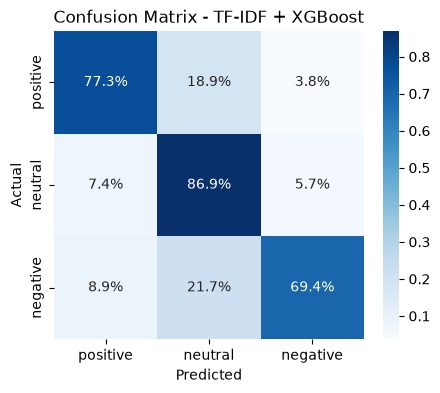

TF-IDF + XGBoost: {'accuracy': 0.7851, 'f1_weighted': 0.785, 'f1_positive': np.float64(0.8054), 'f1_neutral': np.float64(0.7803), 'f1_negative': np.float64(0.7657)}
              precision    recall  f1-score   support

    positive       0.84      0.77      0.81       503
     neutral       0.71      0.87      0.78       511
    negative       0.85      0.69      0.77       405

    accuracy                           0.79      1419
   macro avg       0.80      0.78      0.78      1419
weighted avg       0.80      0.79      0.79      1419



In [20]:
MODEL_NAME = "TF-IDF + XGBoost"

with mlflow.start_run(run_name=MODEL_NAME):
    mlflow.log_params({"tfidf_max_features": 15000, "n_estimators": 300, "max_depth": 6})

    vectorizer = TfidfVectorizer(max_features=15_000, ngram_range=(1, 2), min_df=2)
    X_train = vectorizer.fit_transform(train_df["text"])
    X_test = vectorizer.transform(test_df["text"])

    start = time.time()
    xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                         subsample=0.8, colsample_bytree=0.8,
                         random_state=SEED, n_jobs=-1, verbosity=0)
    xgb.fit(X_train, train_df["label_id"])
    train_time = time.time() - start

    preds = xgb.predict(X_test)
    metrics = evaluate(test_df["label_id"], preds)

    mlflow.log_metrics(metrics)
    mlflow.log_metric("train_time_seconds", round(train_time, 2))
    cm_path = plot_confusion_matrix(test_df["label_id"], preds, MODEL_NAME)
    mlflow.log_artifact(cm_path)

    with open(f"{MODELS_DIR}/tfidf_xgboost.pkl", "wb") as f:
        pickle.dump({"vectorizer": vectorizer, "model": xgb}, f)

print(f"{MODEL_NAME}: {metrics}")
print(classification_report(test_df["label_id"], preds, target_names=["positive", "neutral", "negative"]))
xgb_results = {"name": MODEL_NAME, "metrics": metrics, "train_time": train_time}

## Step 12 — Compare the two baselines

In [21]:
print(f"{'Model':<20} {'F1 (weighted)':>14} {'Accuracy':>10} {'Time (s)':>10}")
print("-" * 58)
for r in [logreg_results, xgb_results]:
    m = r["metrics"]
    print(f"{r['name']:<20} {m['f1_weighted']:>14.4f} {m['accuracy']:>10.4f} {r['train_time']:>10.1f}")

print("\nThese are the numbers every deep learning model (TextCNN, BiLSTM, ...) needs to beat.")
print("See notebooks/03_textcnn.ipynb onwards for those.")

Model                 F1 (weighted)   Accuracy   Time (s)
----------------------------------------------------------
TF-IDF + LogReg              0.7953     0.7956        0.2
TF-IDF + XGBoost             0.7850     0.7851       11.4

These are the numbers every deep learning model (TextCNN, BiLSTM, ...) needs to beat.
See notebooks/03_textcnn.ipynb onwards for those.


## Bonus — preview of what Models 3-6 need instead of TF-IDF

**Not used by anything above.** TF-IDF and Logistic Regression/XGBoost above are complete on their own —
this cell doesn't feed into them and they don't feed into it.

The next 5 notebooks (`03_textcnn.ipynb` onwards) can't use TF-IDF at all, because TF-IDF collapses a whole
headline into one flat vector and throws away word order — but TextCNN/BiLSTM/Attention/Transformer all need
to know which word came before which. So they need a different representation: one integer ID *per word*,
in order. This is a preview of that — a simple word-to-integer lookup table (`word2idx`), shown here once so
you've seen it before it shows up as the first step of every notebook from here on.

In [22]:
class SimpleTokenizer:
    """
    The simplest possible tokenizer: lowercase -> strip punctuation -> split on spaces
    -> map each word to an integer ID. Unknown words become <UNK>, short headlines get
    padded with <PAD> up to MAX_LENGTH.
    """

    def __init__(self):
        self.word2idx = {PAD_TOKEN: PAD_IDX, UNK_TOKEN: UNK_IDX}

    def _clean_and_split(self, text):
        text = text.lower()
        text = re.sub(r"https?://\S+", "", text)
        text = re.sub(r"[^a-z0-9\s\-\%\.]", " ", text)
        return text.split()

    def build_vocab(self, texts):
        """Count every word across all training headlines, keep the VOCAB_SIZE most common."""
        counts = Counter()
        for text in texts:
            counts.update(self._clean_and_split(text))

        for idx, (word, _freq) in enumerate(counts.most_common(VOCAB_SIZE - 2), start=2):
            self.word2idx[word] = idx

    def encode(self, text):
        """Turn one headline into a fixed-length list of integers."""
        words = self._clean_and_split(text)
        ids = [self.word2idx.get(w, UNK_IDX) for w in words]
        ids = ids[:MAX_LENGTH]                             # cut if too long
        ids = ids + [PAD_IDX] * (MAX_LENGTH - len(ids))     # pad if too short
        return ids


tokenizer = SimpleTokenizer()
tokenizer.build_vocab(train_df["text"].tolist())   # fit on TRAIN only — never val/test
print(f"Vocabulary size: {len(tokenizer.word2idx)}")

# quick demo
example = "Reliance Industries posts record quarterly profit"
print(f"\n'{example}'")
print(f"-> {tokenizer.encode(example)[:8]} ... (padded to {MAX_LENGTH})")

with open(f"{MODELS_DIR}/tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

Vocabulary size: 9343

'Reliance Industries posts record quarterly profit'
-> [221, 123, 135, 165, 636, 15, 0, 0] ... (padded to 128)
